<a href="https://colab.research.google.com/github/francji1/01RAD/blob/main/HW/01RAD_Ex08_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01RAD - Homework 08: Robust regression, masking and the least weighted squares

The homework continues Exercise 08, Sections 5–6 (influence measures, masking, M-estimators, LTS).
- **Part A** (data): the Hawkins–Bradu–Kass data, where the classical diagnostics fail and robust methods do not.
- **Part B** (simulation): is the **least weighted squares** estimator (LWS) consistent, how efficient is it, and what happens with contaminated data?

Write a short answer in a markdown cell after each task: bullets, numbers from your output, your interpretation.

## Submission
**Individual work. Deadline: Sunday 29 November 2026, 23:59.** Fork `francji1/01RAD`, save your notebook into the `HW/` folder as `01RAD_Ex08_HW_<Surname>.ipynb` (without the brackets) and open a pull request to `main` that adds this one file only (details in `HW/README.md`). Python or R, as you prefer.

## Least weighted squares
- Order the squared residuals of a candidate $\mathbf{b}$: $r^2_{(1)}(\mathbf{b}) \le r^2_{(2)}(\mathbf{b}) \le \dots \le r^2_{(n)}(\mathbf{b})$.
- Choose weights $1 \ge w_1 \ge w_2 \ge \dots \ge w_n \ge 0$ that depend on the **rank** of the residual, not on the observation.
- LWS: $\widehat{\boldsymbol{\beta}}^{LWS} = \arg\min_{\mathbf{b}} \sum_{k=1}^{n} w_k\, r^2_{(k)}(\mathbf{b})$ (J. Á. Víšek).
- Special cases: all $w_k = 1$ is OLS; $w_k = 1$ for $k \le h$ and 0 otherwise is LTS (Exercise 08, Section 6.3).
- Smoothly decreasing weights keep more information than the hard cut of LTS (efficiency), the zero weights at the end keep the robustness (breakdown point about the share of zero weights).
- Algorithm as for LTS: random starts from $m+1$ points, then steps "order the residuals, assign the weights by rank, solve weighted least squares", repeated until $\mathbf{b}$ stops changing; keep the best of all starts.

Helper functions (`lts` as in Exercise 08, `lws` and a weight function) are given below. Use them, or write your own.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import time

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.precision', 4)
np.set_printoptions(precision=4, suppress=True)

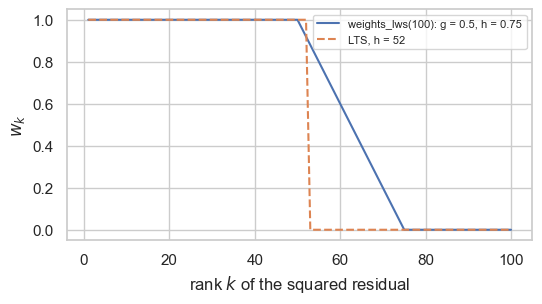

In [2]:
def influence_table(fit, labels):
    """h_ii, t_i, Cook, DFFITS, the largest |DFBETAS| and the rules of p. 132 (Exercise 08, Section 5.3)."""
    inf = fit.get_influence()
    n_, p_ = fit.model.exog.shape
    dfb = pd.DataFrame(inf.dfbetas, columns=fit.model.exog_names)
    tab = pd.DataFrame({'label': labels, 'h_ii': inf.hat_matrix_diag, 't_i': inf.resid_studentized_external,
                        'cook': inf.cooks_distance[0], 'dffits': inf.dffits[0],
                        'max|dfbetas|': dfb.abs().max(axis=1), 'for': dfb.abs().idxmax(axis=1)})
    tab['flag_h'] = tab['h_ii'] > 3 * p_ / n_
    tab['flag_cook'] = tab['cook'] > stats.f.ppf(0.5, p_, n_ - p_)
    tab['flag_dffits'] = tab['dffits'].abs() > 3 * np.sqrt(p_ / (n_ - p_))
    tab['flag_dfbetas'] = tab['max|dfbetas|'] > 1
    return tab


def lts(X, y, h=None, n_starts=500, seed=1):
    """Least trimmed squares: random elemental starts + C-steps (Exercise 08, Section 6.3).
    X includes the column of ones; h defaults to floor((n + m + 2) / 2)."""
    n_, p_ = X.shape
    h = h or (n_ + p_ + 1) // 2
    rng_ = np.random.default_rng(seed)
    best_obj, best_b = np.inf, None
    for _ in range(n_starts):
        idx = rng_.choice(n_, p_, replace=False)
        if abs(np.linalg.det(X[idx])) < 1e-12:
            continue
        b = np.linalg.solve(X[idx], y[idx])
        for _ in range(50):
            keep = np.argsort((y - X @ b) ** 2)[:h]
            b_new = np.linalg.lstsq(X[keep], y[keep], rcond=None)[0]
            if np.allclose(b_new, b):
                break
            b = b_new
        obj = np.sort((y - X @ b) ** 2)[:h].sum()
        if obj < best_obj:
            best_obj, best_b = obj, b
    return best_b


def weights_lws(n, g=0.5, h=0.75):
    """Weights by rank k = 1..n: 1 up to the rank g*n, then linearly down to 0 at the rank h*n, 0 after."""
    k = np.arange(1, n + 1) / n
    return np.clip((h - k) / (h - g), 0, 1)


def lws(X, y, w, n_starts=500, seed=1):
    """Least weighted squares: minimize sum_k w_k r^2_(k); random elemental starts + reweighting steps.
    w = non-increasing weights of length n (w[0] for the smallest squared residual)."""
    n_, p_ = X.shape
    sw = np.sqrt(w)
    rng_ = np.random.default_rng(seed)
    best_obj, best_b = np.inf, None
    for _ in range(n_starts):
        idx = rng_.choice(n_, p_, replace=False)
        if abs(np.linalg.det(X[idx])) < 1e-12:
            continue
        b = np.linalg.solve(X[idx], y[idx])
        for _ in range(50):
            order = np.argsort((y - X @ b) ** 2)               # observation order[k] gets the weight w[k]
            b_new = np.linalg.lstsq(X[order] * sw[:, None], y[order] * sw, rcond=None)[0]
            if np.allclose(b_new, b):
                break
            b = b_new
        obj = np.sort((y - X @ b) ** 2) @ w
        if obj < best_obj:
            best_obj, best_b = obj, b
    return best_b


plt.figure(figsize=(6, 3))
plt.plot(np.arange(1, 101), weights_lws(100), label='weights_lws(100): g = 0.5, h = 0.75')
plt.plot(np.arange(1, 101), (np.arange(1, 101) <= 52).astype(float), ls='--', label='LTS, h = 52')
plt.xlabel('rank $k$ of the squared residual'); plt.ylabel('$w_k$'); plt.legend(fontsize=8)
plt.show()

## Part A: the Hawkins–Bradu–Kass data
`HAWKINS.txt`: 75 observations, three regressors `x1`, `x2`, `x3` and the response `y` (artificial data of Hawkins, Bradu & Kass, 1984; R `robustbase::hbk`). Columns: observation number, `x1`, `x2`, `x3`, `y`.

In [3]:
url_hbk = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/HAWKINS.txt'
hbk = pd.read_csv(url_hbk, sep=r'\s+', header=None, names=['obs', 'x1', 'x2', 'x3', 'y'])
X_hbk = sm.add_constant(hbk[['x1', 'x2', 'x3']].to_numpy())
y_hbk = hbk['y'].to_numpy()
hbk.describe()

,obs,x1,x2,x3,y
count,75.0000,75.0000,75.0000,75.0000,75.0000
mean,38.0000,3.2067,5.5973,7.2307,1.2787
std,21.7945,3.6526,8.2391,11.7403,3.4928
min,1.0000,0.0000,0.0000,0.2000,-1.0000
25%,19.5000,0.8500,1.1000,0.9000,-0.4500
50%,38.0000,1.8000,2.2000,2.1000,0.1000
75%,56.5000,3.1000,3.2500,3.0000,0.7000
max,75.0000,12.0000,34.0000,37.0000,10.8000


### Task A1: look at the data
Draw the pairwise scatter plots (`sns.pairplot`) and $y$ against each regressor. What do you see? Can you guess from the plots alone which observations are unusual, and in which sense (in $\mathbf{x}$, in $y$, or both)?

In [4]:
# A1


### Task A2: OLS and the classical diagnostics
Fit `y ~ x1 + x2 + x3` by OLS. Check the residual plots, then compute the influence measures of Exercise 08 (`influence_table`) and the Bonferroni test of outliers (`outlier_test`).
1. Which observations does each rule flag?
2. Which observations have the largest $|\widehat{t}_i|$, and which the largest $h_{ii}$?
3. Is any regression coefficient significant? What would you conclude about the data from OLS and its diagnostics alone?

In [5]:
# A2


### Task A3: M-estimators
Fit Huber and Tukey (`sm.RLM(y, X, M=sm.robust.norms.HuberT())`, `TukeyBiweight()`, both started from OLS).
1. Compare the coefficients with OLS.
2. Which observations get weights below 0.5? Are they the same as those flagged in A2?
3. Explain the result with the property of M-estimators discussed in Exercise 08, Section 6.2.

In [6]:
# A3


### Task A4: high-breakdown estimators
Fit LTS (`lts`), LWS (`lws` with `weights_lws(75)`) and Tukey started from LTS (`sm.RLM(..., M=sm.robust.norms.TukeyBiweight()).fit(start_params=b_lts, update_scale=False)`).
1. Compare the coefficients of all fits (OLS, Huber, Tukey, LTS, LWS, Tukey from LTS) in one table.
2. **Robust diagnostic plot**: residuals of the LTS fit divided by a robust scale ($\mathrm{MAD} = \mathrm{median}\,|r_i| / 0.6745$, or the scale of the Tukey fit) against $h_{ii}$ of the OLS fit (or against the Mahalanobis distance of $\mathbf{x}_i$). Mark the horizontal lines $\pm 2.5$.
3. Sort the observations into four groups: regular, **vertical outliers** (unusual $y$ only), **good leverage points** (unusual $\mathbf{x}$, $y$ follows the model of the majority), **bad leverage points** (unusual $\mathbf{x}$ and $y$ off the model).
4. Refit OLS without the bad leverage points. Compare with the robust fits and look at its residual plots.

In [7]:
# A4


### Task A5: masking and swamping
In 3–5 sentences: which observations did the OLS diagnostics flag **wrongly** (swamping) and which did they **miss** (masking)? Why? What would have happened if you had deleted the points flagged in A2 and refitted?

## Part B: consistency and efficiency of LWS (simulation)

Model with $m = 4$ regressors and $\boldsymbol{\beta} = (2, 3, -2, 2, 3)^T$:
- column 1: ones (intercept),
- column 2: $\mathrm{Bi}(10, 0.3) + 1$,
- column 3: $N(10, 2^2)$,
- column 4: $N(20, 3^2)$,
- column 5: exponential with mean 8,
- errors $e_i \sim N(0, 1)$, a new $\mathbf{X}$ in every data set.

The function below generates one data set. `eps` is the share of contaminated observations; the contamination is up to you (Task B3), two simple examples are given.

In [8]:
beta_true = np.array([2.0, 3.0, -2.0, 2.0, 3.0])


def generate(n, rng, eps=0.0, kind='vertical'):
    """One data set of the simulation; the first round(eps * n) observations are contaminated."""
    X = np.column_stack([np.ones(n), rng.binomial(10, 0.3, n) + 1, rng.normal(10, 2, n),
                         rng.normal(20, 3, n), rng.exponential(8, n)])
    y = X @ beta_true + rng.normal(0, 1, n)
    k = int(round(eps * n))
    if k > 0 and kind == 'vertical':          # outliers in y only
        y[:k] += rng.normal(30, 5, k)
    if k > 0 and kind == 'leverage':          # bad leverage points: x5 far away, y generated from the original x
        X[:k, 4] = rng.normal(80, 5, k)
    return X, y


rng = np.random.default_rng(2026)
X_demo, y_demo = generate(200, rng, eps=0.1, kind='leverage')
t0 = time.time()
print('OLS:', np.linalg.lstsq(X_demo, y_demo, rcond=None)[0])
print('LTS:', lts(X_demo, y_demo, n_starts=100))
print('LWS:', lws(X_demo, y_demo, weights_lws(200), n_starts=100))
print(f'{time.time() - t0:.1f} s')

OLS: [15.9295  4.0951 -1.908   2.0535  0.4304]
LTS: [ 0.5269  3.1195 -1.8496  1.9889  2.9795]


LWS: [ 1.1062  3.1196 -1.8487  1.9656  2.9757]
0.3 s


### Task B1: your own weight function
Write `weights2(n, g, h)` for $0 < g < h < 1$:
- on the ranks $k \le gn$ the weights decrease linearly from 1 to 0.9,
- on $gn < k \le hn$ they decrease linearly from 0.9 to 0,
- for $k > hn$ they are 0.

Plot it next to `weights_lws`. Fit LWS with `weights2` on the Hawkins–Bradu–Kass data (for example $g = 0.6$, $h = 0.8$) and compare with A4. What is the largest share of contamination such a weight function can, in principle, survive?

In [9]:
# B1


### Task B2: consistency without contamination
For $n \in \{50, 100, 200, 400\}$ (add 800 if your computer allows) generate $R$ data sets ($R = 100$ is enough; with `n_starts=100` the whole task runs a few minutes; fix the seed) and estimate $\boldsymbol{\beta}$ by OLS, LTS and LWS (`weights_lws` and/or your `weights2`).
1. For each method, $n$ and coefficient compute the empirical mean squared error $\widehat{\mathrm{MSE}}(\widehat{\beta}_j) = \frac{1}{R}\sum_{r=1}^{R}(\widehat{\beta}_j^{(r)} - \beta_j)^2$, and the empirical bias.
2. Plot $\widehat{\mathrm{MSE}}$ against $n$ on log–log axes (one panel per coefficient or the sum over the slopes). A consistent estimator has $\mathrm{MSE} \to 0$; for $\sqrt{n}$-consistency the lines have slope about $-1$. What do you see?
3. **Relative efficiency** $\mathrm{MSE}(\text{OLS}) / \mathrm{MSE}(\text{method})$: how much precision do LTS and LWS lose when the data are clean? Which of them loses less, and why?

In [10]:
# B2


### Task B3: contamination
Repeat B2 with **5 %, 10 % and 20 %** of contaminated observations, for at least two kinds of contamination: outliers in $y$ only, and bad leverage points (the two kinds in `generate`, or your own design; describe it). Add Huber (`sm.RLM`) to the methods.
1. Which estimators stay consistent ($\mathrm{MSE} \to 0$), which have a bias that does not vanish with $n$?
2. Which coefficients are affected by the vertical outliers? (Hint: the intercept.)
3. At which share of contamination does LWS with `weights_lws` (zero weights for the top 25 % of ranks) break down? Try 30 %.

In [11]:
# B3


### Task B4: summary
In 4–6 sentences: robustness versus efficiency, what LWS adds to LTS, when you would use OLS with diagnostics, when a robust fit, and what the weights of a robust fit tell you about the data.